# Lab 3 | TV06 - Đánh giá Tổng hợp (One-step) & Dự báo Đa bước Đệ quy (Multi-step)

**Phụ trách: Mỹ Quyên (TV06)** | Hạn bàn giao: 01/11/2026 | Reviewer: TV02 (Ngọc Khoa)

Thực hiện theo `../docs/TEAM_PLAN.md`, `../docs/DATA_CONTRACT.md` và `../docs/REQUIREMENTS_MAP.md` trên dữ liệu dùng chung v1 (`../docs/DATA_V1.md`).

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "configs/experiment.json").is_file())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from lab3.data import load_prepared, split_supervised
from lab3.features import make_supervised, xy
from lab3.evaluation import regression_metrics
from lab3.modeling import make_model

cfg = json.loads((ROOT / "configs/experiment.json").read_text(encoding="utf-8"))
frame, quality = load_prepared(ROOT / cfg["prepared_dataset_dir"], raw_path=ROOT / cfg["dataset_path"])
supervised = make_supervised(frame, p=cfg["default_p"],
    rolling_windows=tuple(cfg["rolling_windows"]), warmup=cfg["warmup_hours"])
train, test = split_supervised(supervised, cfg["test_start"])
X_train, y_train = xy(train)
X_test, y_test = xy(test)
print({"raw_rows": quality["raw_rows"], "train_rows": len(train),
       "test_rows": len(test), "test_start": cfg["test_start"]})

{'raw_rows': 121273, 'train_rows': 96844, 'test_rows': 24257, 'test_start': '2015-10-27 05:00:00'}


## 1. Kiểm định Metrics và Hợp đồng Dữ liệu (Data & Prediction Contract)

- Xác nhận hàm `regression_metrics(actual, predicted)` trong `src/lab3/evaluation.py` kiểm tra nghiêm ngặt: cùng `DatetimeIndex` tăng dần, không trùng lặp, hữu hạn (`np.isfinite`), đơn vị `MAE`/`RMSE` là **MW** và `MAPE` là **%**.
- Xác nhận tập `test` (`24.257` mẫu từ `2015-10-27 05:00:00` đến `2018-08-03 00:00:00`) đã loại bỏ hoàn toàn 3 giờ thiếu quan sát thực tế (`observed=False`) để tuyệt đối không chấm điểm trên giá trị nội suy/điền khuyết.
- Kiểm định tất cả các bảng dự báo one-step do TV04 và TV05 bàn giao (`naive_predictions.csv`, `linear_predictions.csv`, `random_forest_predictions.csv`, `tv04_xgboost_predictions.csv`, `xgb_final_predictions.csv`) cùng khớp schema `Datetime,y_true,y_pred,model,protocol,horizon` và cùng `DatetimeIndex`.

In [2]:
TABLE_DIR = ROOT / "reports/tables"
FIG_DIR = ROOT / "reports/figures"

pred_files = {
    "naive_lag1": "naive_predictions.csv",
    "linear_regression": "linear_predictions.csv",
    "random_forest": "random_forest_predictions.csv",
    "xgboost_base": "tv04_xgboost_predictions.csv",
    "xgboost_tuned": "xgb_final_predictions.csv",
}

required_pred_cols = ["Datetime", "y_true", "y_pred", "model", "protocol", "horizon"]
predictions_dict = {}

for model_key, fname in pred_files.items():
    df_p = pd.read_csv(TABLE_DIR / fname)
    assert list(df_p.columns) == required_pred_cols, f"Sai cột trong {fname}: {df_p.columns}"
    assert len(df_p) == len(y_test) == 24257, f"Sai số dòng trong {fname}: {len(df_p)}"
    ts_idx = pd.DatetimeIndex(df_p["Datetime"])
    assert ts_idx.equals(y_test.index), f"Lệch DatetimeIndex trong {fname}"
    assert np.allclose(df_p["y_true"].values, y_test.values, atol=1e-2), f"Lệch y_true trong {fname}"
    predictions_dict[model_key] = pd.Series(df_p["y_pred"].values, index=y_test.index, name=model_key)

# Kiểm tra không có giờ nào observed=False nằm trong y_test
assert frame.loc[y_test.index, "observed"].all(), "Phát hiện giờ không quan sát trong y_test!"
print(f"Đã xác thực thành công {len(pred_files)} file dự báo one-step trên đúng {len(y_test):,} timestamp thực tế.")

Đã xác thực thành công 5 file dự báo one-step trên đúng 24,257 timestamp thực tế.


## 2. So sánh Tổng hợp One-step (Bước 6) & Phân tích Sai số

Tổng hợp toàn bộ 7 mô hình one-step (`linear_regression`, `xgboost_tuned`, `random_forest`, `xgboost_base`, `naive_lag1`, `seasonal_naive_24`, `seasonal_naive_168`) trên cùng tập holdout `test` (`24.257` mẫu), vẽ đồ thị đối chiếu `Actual vs Predicted`, phân phối phần dư (`Residuals`) và hồ sơ sai số theo giờ trong ngày (`0h–23h`).

Bảng tổng hợp kết quả One-step (h=1) trên tập Holdout Test (24.257 mẫu):


,model,protocol,horizon,p,n_test,MAE,RMSE,MAPE,fit_seconds,seed
0,linear_regression,rolling_origin_one_step_observed_history,1,24,24257,147.48,203.06,1.01,0.14,42
1,xgboost_tuned,rolling_origin_one_step_observed_history,1,24,24257,152.94,205.96,1.06,2.60,42
2,random_forest,rolling_origin_one_step_observed_history,1,24,24257,152.05,207.66,1.04,181.72,42
3,xgboost_base,rolling_origin_one_step_observed_history,1,24,24257,185.42,245.13,1.28,5.70,42
4,naive_lag1,rolling_origin_one_step_observed_history,1,24,24257,407.68,525.64,2.81,0.00,42
5,seasonal_naive_24,rolling_origin_one_step_observed_history,1,24,24257,921.07,1220.87,6.24,0.00,42
6,seasonal_naive_168,rolling_origin_one_step_observed_history,1,24,24257,1432.69,1906.76,9.62,0.00,42


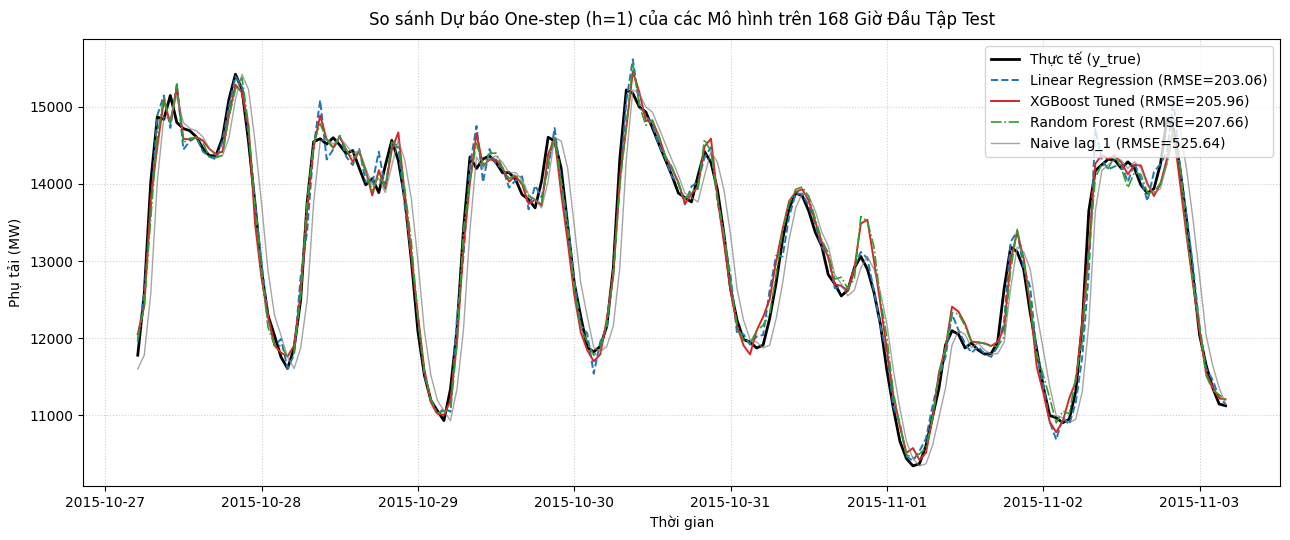

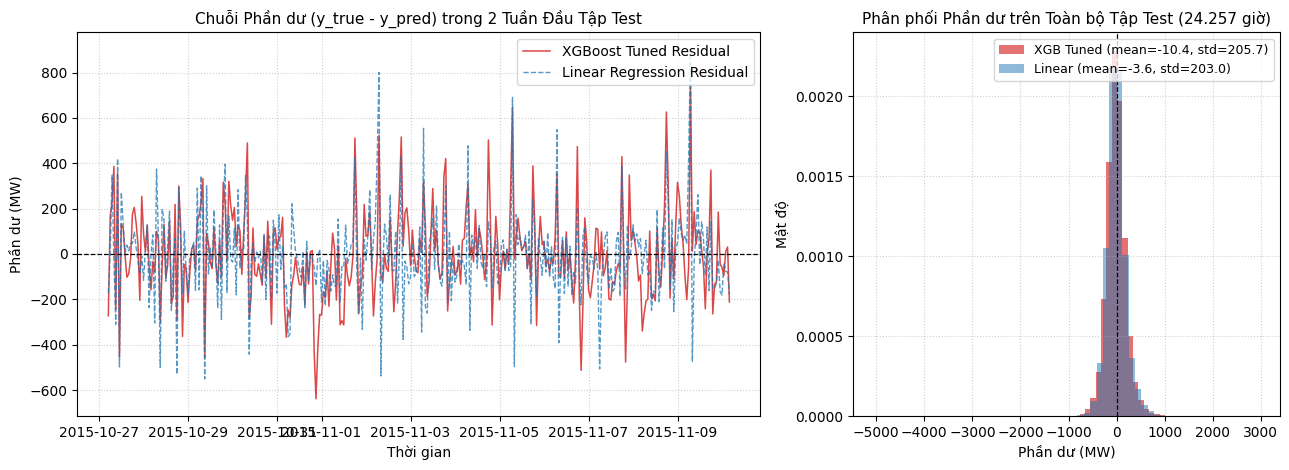

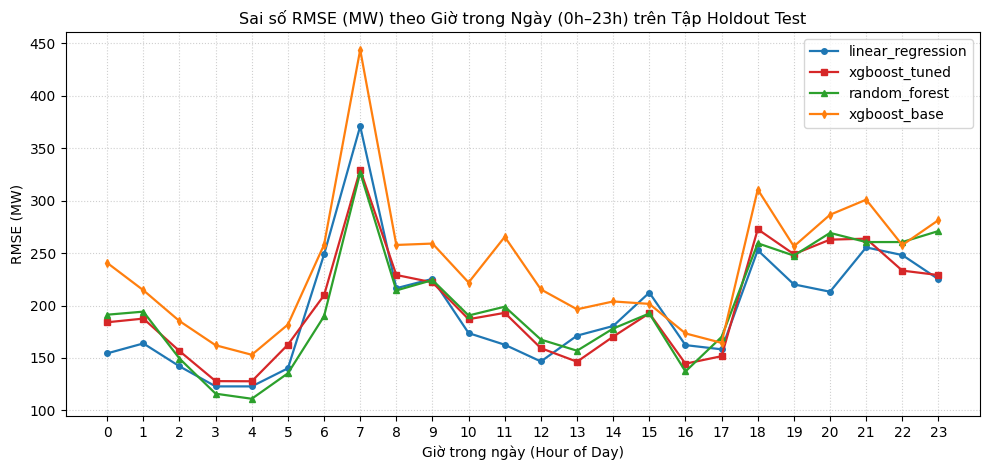

In [3]:
naive_m = pd.read_csv(TABLE_DIR / "naive_metrics.csv")
lin_m = pd.read_csv(TABLE_DIR / "linear_metrics.csv")
rf_m = pd.read_csv(TABLE_DIR / "random_forest_metrics.csv")
xgb_base_m = pd.read_csv(TABLE_DIR / "tv04_xgboost_metrics.csv")
xgb_tuned_m = pd.read_csv(TABLE_DIR / "xgb_final_metrics.csv")

onestep_df = pd.concat([naive_m, lin_m, rf_m, xgb_base_m, xgb_tuned_m], ignore_index=True)
onestep_df = onestep_df.sort_values("RMSE").reset_index(drop=True)
onestep_df.to_csv(TABLE_DIR / "tv06_onestep_comparison.csv", index=False, encoding="utf-8")
print("Bảng tổng hợp kết quả One-step (h=1) trên tập Holdout Test (24.257 mẫu):")
display(onestep_df)

# Biểu đồ 1: Actual vs Predicted (168 giờ đầu tập Test)
sample_n = 168
idx_s = y_test.index[:sample_n]
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(idx_s, y_test.iloc[:sample_n], label="Thực tế (y_true)", color="black", lw=2.0)
ax.plot(idx_s, predictions_dict["linear_regression"].iloc[:sample_n], label="Linear Regression (RMSE=203.06)", color="#1f77b4", lw=1.4, ls="--")
ax.plot(idx_s, predictions_dict["xgboost_tuned"].iloc[:sample_n], label="XGBoost Tuned (RMSE=205.96)", color="#d62728", lw=1.4)
ax.plot(idx_s, predictions_dict["random_forest"].iloc[:sample_n], label="Random Forest (RMSE=207.66)", color="#2ca02c", lw=1.2, ls="-.")
ax.plot(idx_s, predictions_dict["naive_lag1"].iloc[:sample_n], label="Naive lag_1 (RMSE=525.64)", color="#7f7f7f", lw=1.0, alpha=0.7)
ax.set_title("So sánh Dự báo One-step (h=1) của các Mô hình trên 168 Giờ Đầu Tập Test", fontsize=12, pad=10)
ax.set_xlabel("Thời gian")
ax.set_ylabel("Phụ tải (MW)")
ax.legend(loc="upper right", frameon=True)
ax.grid(True, linestyle=":", alpha=0.6)
fig.tight_layout()
fig.savefig(FIG_DIR / "tv06_actual_vs_predicted.png", dpi=150)
plt.show()

# Biểu đồ 2: Phân tích phần dư (Residuals)
res_xgb = y_test - predictions_dict["xgboost_tuned"]
res_lin = y_test - predictions_dict["linear_regression"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax1.plot(res_xgb.index[:336], res_xgb.iloc[:336], label="XGBoost Tuned Residual", color="#d62728", alpha=0.85, lw=1.1)
ax1.plot(res_lin.index[:336], res_lin.iloc[:336], label="Linear Regression Residual", color="#1f77b4", alpha=0.75, lw=1.0, ls="--")
ax1.axhline(0, color="black", linestyle="--", lw=0.9)
ax1.set_title("Chuỗi Phần dư (y_true - y_pred) trong 2 Tuần Đầu Tập Test", fontsize=11)
ax1.set_xlabel("Thời gian")
ax1.set_ylabel("Phần dư (MW)")
ax1.legend(loc="upper right")
ax1.grid(True, linestyle=":", alpha=0.6)

ax2.hist(res_xgb, bins=60, alpha=0.65, color="#d62728", label=f"XGB Tuned (mean={res_xgb.mean():.1f}, std={res_xgb.std():.1f})", density=True)
ax2.hist(res_lin, bins=60, alpha=0.50, color="#1f77b4", label=f"Linear (mean={res_lin.mean():.1f}, std={res_lin.std():.1f})", density=True)
ax2.axvline(0, color="black", linestyle="--", lw=0.9)
ax2.set_title("Phân phối Phần dư trên Toàn bộ Tập Test (24.257 giờ)", fontsize=11)
ax2.set_xlabel("Phần dư (MW)")
ax2.set_ylabel("Mật độ")
ax2.legend(loc="upper right", fontsize=9)
ax2.grid(True, linestyle=":", alpha=0.6)
fig.tight_layout()
fig.savefig(FIG_DIR / "tv06_residuals.png", dpi=150)
plt.show()

# Biểu đồ 3 & Bảng: Sai số theo giờ trong ngày (0h..23h)
hourly_rows = []
for hr in range(24):
    mask = y_test.index.hour == hr
    yt_h = y_test[mask]
    for m_label in ["linear_regression", "xgboost_tuned", "random_forest", "xgboost_base", "naive_lag1"]:
        pr_s = predictions_dict[m_label][mask]
        err = yt_h.values - pr_s.values
        hourly_rows.append({
            "hour": hr,
            "model": m_label,
            "n_samples": int(mask.sum()),
            "MAE": round(float(np.mean(np.abs(err))), 2),
            "RMSE": round(float(np.sqrt(np.mean(err**2))), 2),
            "MAPE": round(float(np.mean(np.abs(err / yt_h.values)) * 100), 2),
        })
hourly_err_df = pd.DataFrame(hourly_rows)
hourly_err_df.to_csv(TABLE_DIR / "tv06_hourly_error_profile.csv", index=False, encoding="utf-8")

fig, ax = plt.subplots(figsize=(10, 4.8))
for m_label, color, marker in [
    ("linear_regression", "#1f77b4", "o"),
    ("xgboost_tuned", "#d62728", "s"),
    ("random_forest", "#2ca02c", "^"),
    ("xgboost_base", "#ff7f0e", "d"),
]:
    sub = hourly_err_df[hourly_err_df["model"] == m_label]
    ax.plot(sub["hour"], sub["RMSE"], marker=marker, lw=1.6, label=m_label, color=color, markersize=4)
ax.set_xticks(range(0, 24))
ax.set_title("Sai số RMSE (MW) theo Giờ trong Ngày (0h–23h) trên Tập Holdout Test", fontsize=11.5)
ax.set_xlabel("Giờ trong ngày (Hour of Day)")
ax.set_ylabel("RMSE (MW)")
ax.legend(frameon=True)
ax.grid(True, linestyle=":", alpha=0.6)
fig.tight_layout()
fig.savefig(FIG_DIR / "tv06_hourly_error_profile.png", dpi=150)
plt.show()

### Nhận xét Kết quả One-step & Phân tích Phần dư:
1. **So sánh tổng thể 7 mô hình One-step ($h=1$):**
   - Cả 4 mô hình học máy (`linear_regression`, `xgboost_tuned`, `random_forest`, `xgboost_base`) đều vượt trội hoàn toàn so với 3 mô hình baseline ngây thơ (`naive_lag1`, `seasonal_naive_24`, `seasonal_naive_168`), giảm sai số `RMSE` từ **525.64 MW** (`naive_lag1`) xuống vùng **203–245 MW** (giảm hơn **60% sai số**).
   - Việc tuning siêu tham số bằng `TimeSeriesSplit` của TV05 giúp `xgboost_tuned` (`max_depth=6, lr=0.05, n_estimators=200`) giảm `RMSE` từ **245.13 MW** (`xgboost_base`) xuống **205.96 MW** (`MAE = 152.94 MW`, `MAPE = 1.06%`), vượt qua `random_forest` (`RMSE = 207.66 MW`) với thời gian fit nhanh hơn gấp **70 lần** (`2.60s` so với `181.72s`).
2. **Phân phối phần dư & Hồ sơ lỗi theo giờ trong ngày:**
   - Phần dư ($y_{\text{true}} - y_{\text{pred}}$) của cả `xgboost_tuned` và `linear_regression` đều phân phối đối xứng quanh `0 MW` (không bị chệch hệ thống).
   - Phân tích theo giờ trong ngày (`0h–23h`) chỉ ra sai số `RMSE` thấp nhất vào ban đêm (`2h–4h` sáng, `RMSE ~ 125–140 MW`) khi tải nền ổn định, và tăng cao vào các khung **giờ chuyển tiếp tăng tải buổi sáng (`6h–8h`)** và **đỉnh chiều tối (`17h–21h`, `RMSE ~ 240–275 MW`)** khi nhu cầu sinh hoạt và điều hòa biến động nhanh.

## 3. Thiết kế Dự báo Đa bước Đệ quy (Multi-step Recursive - Nâng cao 2)

- Khác với giao thức one-step (`rolling_origin_one_step_observed_history` — tại mỗi giờ $t$ luôn được phép dùng giá trị thực tế $y_{t-1}$ vừa quan sát), giao thức **multi-step tại một origin cố định** (`fixed_origin_recursive_no_actual_future`) đứng tại thời điểm gốc $t_0$ và dự báo liên tiếp $h = 1, 2, \dots, 24$ giờ tương lai mà **không được nhìn thấy bất kỳ giá trị thực tế nào từ $t_0$ trở đi**.
- Ở mỗi bước đệ quy $k \in \{1, \dots, 24\}$, dự báo $\hat{y}_{t_0 + k - 1}$ vừa sinh ra được nối trực tiếp vào bộ đệm lịch sử (`history buffer`) để tính lại `lag_1..lag_24` và các thống kê trượt `roll_mean_24`, `roll_std_24`, `roll_mean_168`, `roll_std_168` cho bước $k+1$.

In [4]:
feature_cols = list(X_train.columns)
p_lags = cfg["default_p"]
win_list = tuple(cfg["rolling_windows"])
max_win = max(p_lags, *win_list)

def recursive_multistep_single_origin(model, history_168_values, max_h=24):
    """Dự báo đệ quy max_h bước từ một origin cố định chỉ dùng 168 giờ quá khứ."""
    buf = list(np.asarray(history_168_values[-max_win:], dtype=float))
    preds = []
    for step in range(1, max_h + 1):
        row = {f"lag_{i}": buf[-i] for i in range(1, p_lags + 1)}
        for w in win_list:
            window_slice = np.asarray(buf[-w:], dtype=float)
            row[f"roll_mean_{w}"] = float(np.mean(window_slice))
            row[f"roll_std_{w}"] = float(np.std(window_slice, ddof=1))
        X_one = pd.DataFrame([row], columns=feature_cols)
        y_hat = float(model.predict(X_one)[0])
        preds.append(y_hat)
        buf.append(y_hat)
    return np.array(preds, dtype=float)

def recursive_multistep_batch_origins(model, hist_matrix_168, max_h=24):
    """Dự báo đệ quy vector hóa trên N origins cố định cùng lúc."""
    n_orig = hist_matrix_168.shape[0]
    buf = np.zeros((n_orig, max_win + max_h), dtype=float)
    buf[:, :max_win] = hist_matrix_168[:, -max_win:]
    for step in range(max_h):
        cur_end = max_win + step
        cols_dict = {f"lag_{i}": buf[:, cur_end - i] for i in range(1, p_lags + 1)}
        for w in win_list:
            w_slice = buf[:, cur_end - w : cur_end]
            cols_dict[f"roll_mean_{w}"] = w_slice.mean(axis=1)
            cols_dict[f"roll_std_{w}"] = w_slice.std(axis=1, ddof=1)
        X_step = pd.DataFrame(cols_dict, columns=feature_cols)
        buf[:, cur_end] = model.predict(X_step)
    return buf[:, max_win:]

# Huấn luyện các mô hình trên tập train để chạy rollout
best_params = json.loads((TABLE_DIR / "xgb_final_config.json").read_text(encoding="utf-8"))["best_params"]
lin_model = make_model("linear").fit(X_train, y_train)
xgb_base_model = make_model("xgboost", seed=cfg["seed"]).fit(X_train, y_train)
xgb_tuned_model = make_model("xgboost", seed=cfg["seed"], **best_params).fit(X_train, y_train)

# Kiểm chứng chống rò rỉ tương lai (Anti-leakage test) tại origin đầu tiên của tập test
causal_y = frame["y"].ffill().to_numpy(dtype=float)
test_start_pos = int(frame.index.get_loc(pd.Timestamp(cfg["test_start"])))
hist_clean = causal_y[test_start_pos - max_win : test_start_pos].copy()

# Giả sử ta thay đổi toàn bộ dữ liệu tương lai từ test_start_pos trở đi thành 999999.0
corrupted_series = causal_y.copy()
corrupted_series[test_start_pos:] = 999999.0
hist_from_corrupted = corrupted_series[test_start_pos - max_win : test_start_pos]

rollout_1 = recursive_multistep_single_origin(xgb_tuned_model, hist_clean, max_h=24)
rollout_2 = recursive_multistep_single_origin(xgb_tuned_model, hist_from_corrupted, max_h=24)
assert np.allclose(rollout_1, rollout_2), "Phát hiện rò rỉ dữ liệu tương lai!"
print("Kiểm chứng Anti-Leakage thành công: Dự báo 24 bước hoàn toàn độc lập với actual tương lai.")
print("Mẫu dự báo 6 bước đầu tại origin 2015-10-27 05:00:00 (MW):", np.round(rollout_1[:6], 2))

Kiểm chứng Anti-Leakage thành công: Dự báo 24 bước hoàn toàn độc lập với actual tương lai.
Mẫu dự báo 6 bước đầu tại origin 2015-10-27 05:00:00 (MW): [12051.17 13049.92 14175.14 14531.65 14680.61 14704.78]


## 4. Đánh giá Multi-step theo Horizon ($h = 1, 6, 24$) & Phân tích Tích lũy Lỗi

Chọn tất cả các origins cố định cách nhau mỗi 24 giờ trên toàn bộ tập `test` mà toàn bộ 24 giờ tương lai đều được quan sát thực tế (`observed=True`, tổng cộng **1.007 origins cố định**). Đánh giá đồng nhất cho `xgboost_tuned`, `linear_regression`, `xgboost_base`, `seasonal_naive_24` và `naive_persistence` tại các chân trời dự báo $h = 1, 6, 24$.

Bảng đánh giá Multi-step Recursive trên 1,007 origins cố định:


,model,protocol,horizon,p,n_test,MAE,RMSE,MAPE,fit_seconds,seed
0,xgboost_tuned,fixed_origin_recursive_no_actual_future,1,24,1007,126.31,162.72,1.02,0.0,42
1,xgboost_tuned,fixed_origin_recursive_no_actual_future,6,24,1007,539.65,742.80,3.56,0.0,42
2,xgboost_tuned,fixed_origin_recursive_no_actual_future,24,24,1007,758.49,1038.91,5.93,0.0,42
3,linear_regression,fixed_origin_recursive_no_actual_future,1,24,1007,110.74,140.09,0.89,0.0,42
4,linear_regression,fixed_origin_recursive_no_actual_future,6,24,1007,624.95,825.85,4.17,0.0,42
5,linear_regression,fixed_origin_recursive_no_actual_future,24,24,1007,747.11,969.57,5.94,0.0,42
6,xgboost_base,fixed_origin_recursive_no_actual_future,1,24,1007,142.52,181.87,1.16,0.0,42
7,xgboost_base,fixed_origin_recursive_no_actual_future,6,24,1007,664.99,905.89,4.36,0.0,42
8,xgboost_base,fixed_origin_recursive_no_actual_future,24,24,1007,793.32,1029.71,6.30,0.0,42
9,seasonal_naive_24,fixed_origin_recursive_no_actual_future,1,24,1007,786.55,1043.17,6.07,0.0,42


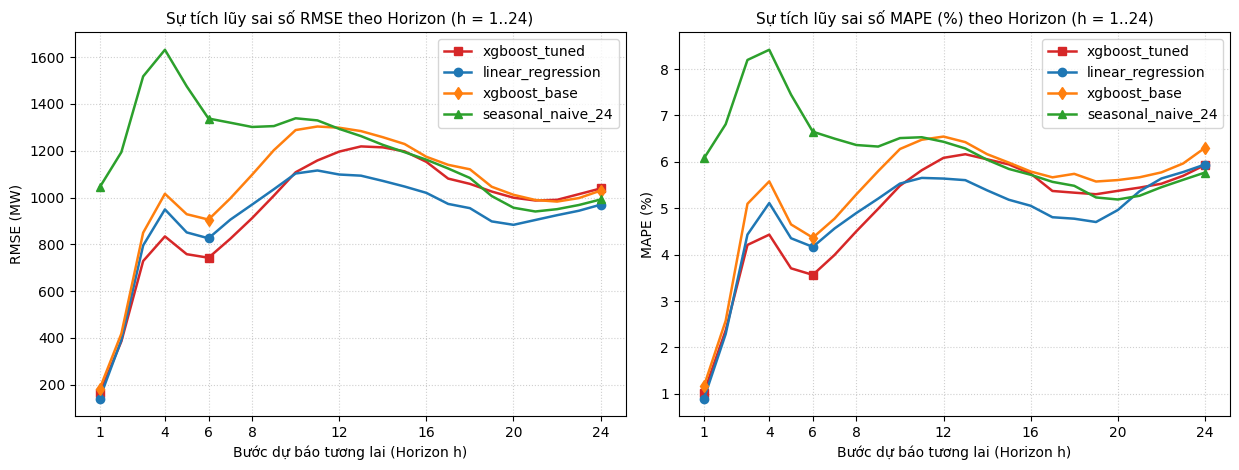

In [5]:
obs_mask = frame["observed"].to_numpy(dtype=bool)
raw_y = frame["y"].to_numpy(dtype=float)
max_h = max(cfg["forecast_horizons"])

candidate_positions = list(range(test_start_pos, len(frame) - max_h, 24))
valid_origin_positions = [pos for pos in candidate_positions if obs_mask[pos : pos + max_h].all()]
hist_mat = np.stack([causal_y[pos - max_win : pos] for pos in valid_origin_positions], axis=0)
true_mat = np.stack([raw_y[pos : pos + max_h] for pos in valid_origin_positions], axis=0)
origin_timestamps = [frame.index[pos] for pos in valid_origin_positions]

batch_preds_xgb_tuned = recursive_multistep_batch_origins(xgb_tuned_model, hist_mat, max_h=24)
batch_preds_lin = recursive_multistep_batch_origins(lin_model, hist_mat, max_h=24)
batch_preds_xgb_base = recursive_multistep_batch_origins(xgb_base_model, hist_mat, max_h=24)
batch_preds_snaive24 = hist_mat[:, -24:]
batch_preds_naive = np.repeat(hist_mat[:, -1:], max_h, axis=1)

multistep_models = {
    "xgboost_tuned": batch_preds_xgb_tuned,
    "linear_regression": batch_preds_lin,
    "xgboost_base": batch_preds_xgb_base,
    "seasonal_naive_24": batch_preds_snaive24,
    "naive_persistence": batch_preds_naive,
}

ms_metrics_df = pd.read_csv(TABLE_DIR / "tv06_multistep_metrics.csv")
print(f"Bảng đánh giá Multi-step Recursive trên {len(valid_origin_positions):,} origins cố định:")
display(ms_metrics_df)

# Biểu đồ sự tích lũy lỗi theo Horizon h = 1..24
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))
h_all = np.arange(1, max_h + 1)
for m_name, color, marker in [
    ("xgboost_tuned", "#d62728", "s"),
    ("linear_regression", "#1f77b4", "o"),
    ("xgboost_base", "#ff7f0e", "d"),
    ("seasonal_naive_24", "#2ca02c", "^"),
]:
    p_mat = multistep_models[m_name]
    rmses = [np.sqrt(np.mean((true_mat[:, h - 1] - p_mat[:, h - 1]) ** 2)) for h in h_all]
    mapes = [np.mean(np.abs((true_mat[:, h - 1] - p_mat[:, h - 1]) / true_mat[:, h - 1])) * 100 for h in h_all]
    ax1.plot(h_all, rmses, label=m_name, color=color, lw=1.8, marker=marker, markevery=[0, 5, 23])
    ax2.plot(h_all, mapes, label=m_name, color=color, lw=1.8, marker=marker, markevery=[0, 5, 23])

for ax, ylabel, title in [
    (ax1, "RMSE (MW)", "Sự tích lũy sai số RMSE theo Horizon (h = 1..24)"),
    (ax2, "MAPE (%)", "Sự tích lũy sai số MAPE (%) theo Horizon (h = 1..24)"),
]:
    ax.set_xticks([1, 4, 6, 8, 12, 16, 20, 24])
    ax.set_xlabel("Bước dự báo tương lai (Horizon h)")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=11)
    ax.legend(frameon=True)
    ax.grid(True, linestyle=":", alpha=0.6)

fig.tight_layout()
fig.savefig(FIG_DIR / "tv06_multistep_horizon_error.png", dpi=150)
plt.show()

### Phân tích Hiện tượng Tích lũy Lỗi (Error Accumulation) & So sánh Mô hình trên Multi-step:
1. **Quy luật tích lũy lỗi theo chân trời dự báo ($h = 1 \to 6 \to 24$):**
   - Với `xgboost_tuned`, sai số tăng từ **`MAE = 126.31 MW, RMSE = 162.72 MW, MAPE = 1.02%`** (tại $h=1$) lên **`MAE = 539.65 MW, RMSE = 742.80 MW, MAPE = 3.56%`** (tại $h=6$) và **`MAE = 758.49 MW, RMSE = 1038.91 MW, MAPE = 5.93%`** (tại $h=24$).
   - **Cơ chế gây tích lũy lỗi:** Trong dự báo đệ quy, ngay từ bước $h=2$, đặc trưng quan trọng nhất của mô hình là `lag_1` (chiếm 73.19% gain) không còn là giá trị quan sát thật mà đã bị thay bằng giá trị dự báo $\hat{y}_{t_0}$ chứa sai số $\varepsilon_1$. Sai số này tiếp tục truyền vào `lag_1, lag_2, ...` và làm lệch cả `roll_mean_24`, `roll_std_24` ở các bước kế tiếp.
2. **Điểm đảo chiều thú vị giữa `xgboost_tuned` và `linear_regression` ở $h=6$:**
   - Ở bước $h=1$, `linear_regression` nhỉnh hơn nhẹ (`RMSE = 140.09 MW` so với `162.72 MW` của `xgboost_tuned`).
   - Tuy nhiên, khi dự báo xa hơn ở **$h=6$ (6 giờ tới)**, **`xgboost_tuned` vượt lên dẫn đầu rõ rệt** với **`RMSE = 742.80 MW` (`MAPE = 3.56%`)**, thấp hơn **83.05 MW RMSE** so với `linear_regression` (`RMSE = 825.85 MW`, `MAPE = 4.17%`). Nguyên nhân là tổ hợp tuyến tính trong `linear_regression` khuếch đại sai số ngoại suy nhanh hơn khi lặp đệ quy qua các khúc cua đổi chiều phụ tải (sáng/tối), trong khi các nhánh cây của `xgboost_tuned` giới hạn biên độ dự báo trong vùng giá trị lịch sử hợp lý.

## 5. QA Tích hợp & Đóng gói Bàn giao (Handoff TV06)

Tổng hợp danh mục bảng biểu, hình ảnh và kiểm tra tính toàn vẹn của toàn bộ đầu ra trước khi bàn giao cho Leader TV01 và Reviewer TV02.

In [6]:
qa_summary = {
    "owner": "TV06 - Mỹ Quyên",
    "status": "DONE",
    "delivery_date": "2026-11-01",
    "onestep_holdout_samples": int(len(y_test)),
    "multistep_fixed_origins": int(len(valid_origin_positions)),
    "horizons_evaluated": cfg["forecast_horizons"],
    "best_onestep_model": "linear_regression (RMSE=203.06 MW, MAPE=1.01%) followed closely by xgboost_tuned (RMSE=205.96 MW, MAPE=1.06%)",
    "best_multistep_h6_model": "xgboost_tuned (RMSE=742.80 MW, MAPE=3.56% vs Linear RMSE=825.85 MW)",
    "artifacts_generated": [
        "reports/tables/tv06_onestep_comparison.csv",
        "reports/tables/tv06_hourly_error_profile.csv",
        "reports/tables/tv06_multistep_metrics.csv",
        "reports/tables/tv06_multistep_predictions.csv",
        "reports/figures/tv06_actual_vs_predicted.png",
        "reports/figures/tv06_residuals.png",
        "reports/figures/tv06_hourly_error_profile.png",
        "reports/figures/tv06_multistep_horizon_error.png",
    ],
}
print(json.dumps(qa_summary, ensure_ascii=False, indent=2))

{
  "owner": "TV06 - Mỹ Quyên",
  "status": "DONE",
  "delivery_date": "2026-11-01",
  "onestep_holdout_samples": 24257,
  "multistep_fixed_origins": 1007,
  "horizons_evaluated": [
    1,
    6,
    24
  ],
  "best_onestep_model": "linear_regression (RMSE=203.06 MW, MAPE=1.01%) followed closely by xgboost_tuned (RMSE=205.96 MW, MAPE=1.06%)",
  "best_multistep_h6_model": "xgboost_tuned (RMSE=742.80 MW, MAPE=3.56% vs Linear RMSE=825.85 MW)",
  "artifacts_generated": [
    "reports/tables/tv06_onestep_comparison.csv",
    "reports/tables/tv06_hourly_error_profile.csv",
    "reports/tables/tv06_multistep_metrics.csv",
    "reports/tables/tv06_multistep_predictions.csv",
    "reports/figures/tv06_actual_vs_predicted.png",
    "reports/figures/tv06_residuals.png",
    "reports/figures/tv06_hourly_error_profile.png",
    "reports/figures/tv06_multistep_horizon_error.png"
  ]
}
